# Machine Failure Early-Warning — Analisis

Notebook ini memeriksa apakah data observasi mesin bisa dipakai untuk memperingatkan
kegagalan tujuh hari ke depan.

**Cara memakai notebook ini.** Jalankan sel satu per satu dari atas ke bawah.
Setiap bagian diawali penjelasan: apa yang sedang diperiksa, mengapa, dan apa arti hasilnya.
Jangan melompati sel, karena sel di bawah memakai hasil sel di atasnya.

**Yang perlu diketahui sebelum mulai.** Data ini berbentuk *panel*: satu mesin diamati
berkali-kali sepanjang waktu. Tiap baris adalah satu observasi dari satu mesin pada satu
waktu. Kolom `fails_within_7d` bernilai 1 jika mesin itu tercatat gagal dalam tujuh hari
setelah observasi, dan 0 jika tidak.

Urutan pemeriksaan di notebook ini sengaja dibuat begini:

1. Kenali bentuk data
2. Periksa kebersihan data
3. Periksa target
4. **Periksa asal-usul tiap kolom** — bagian terpenting
5. Bagi data dengan benar
6. Bangun pembanding sederhana
7. Bangun model
8. Terjemahkan ke satuan operasional

Langkah 4 ditempatkan sebelum pemodelan dengan sengaja. Model yang dibangun di atas kolom
yang bermasalah akan menghasilkan angka bagus yang menyesatkan, dan kesalahan itu sulit
terdeteksi setelah model jadi.

## Bagian 0 — Persiapan

Sel di bawah memuat pustaka yang dipakai sepanjang notebook.

- `pandas` menangani tabel data
- `numpy` menangani perhitungan angka
- `matplotlib` menggambar grafik
- `scikit-learn` menyediakan model dan ukuran evaluasi

`RANDOM_STATE = 42` mengunci keacakan. Tanpa ini, hasil bisa sedikit berbeda setiap kali
dijalankan, dan orang lain tidak bisa mereproduksi angka Anda. Angka 42 tidak istimewa;
yang penting nilainya tetap.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

RANDOM_STATE = 42

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Cari folder utama proyek, baik notebook dijalankan dari folder notebooks/ maupun dari akar repo
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "machine_observations.csv"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

print("Folder proyek :", ROOT)
print("Berkas data   :", DATA_PATH)
print("Data ditemukan:", DATA_PATH.exists())

Folder proyek : C:\Users\User\Downloads\machine-failure-early-warning\machine-failure-early-warning
Berkas data   : C:\Users\User\Downloads\machine-failure-early-warning\machine-failure-early-warning\data\machine_observations.csv
Data ditemukan: True


## Bagian 1 — Mengenal bentuk data

Sebelum menghitung apa pun, kita perlu tahu apa yang sedang kita pegang: berapa barisnya,
berapa mesinnya, dan rentang waktunya sampai mana.

`parse_dates` memberi tahu pandas bahwa kolom `observation_timestamp` adalah tanggal,
bukan teks. Tanpa itu, pandas memperlakukannya sebagai kata, sehingga pengurutan waktu
dan selisih hari tidak bisa dihitung.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["observation_timestamp"])

print("Jumlah baris  :", len(df))
print("Jumlah kolom  :", df.shape[1])
print("Jumlah mesin  :", df["machine_id"].nunique())
print("Observasi pertama :", df["observation_timestamp"].min())
print("Observasi terakhir:", df["observation_timestamp"].max())

df.head()

Jumlah baris  : 10414
Jumlah kolom  : 15
Jumlah mesin  : 120
Observasi pertama : 2024-01-01 01:08:00
Observasi terakhir: 2025-02-28 22:57:00


,record_id,machine_id,observation_timestamp,site,machine_class,load_pct,ambient_temp_c,vibration_mm_s,bearing_temp_c,motor_current_a,discharge_pressure_kpa,corrective_orders_14d,unplanned_stops_14d,inspection_interval_days,fails_within_7d
0,REC-000001,M088,2024-01-01 01:08:00,North,A,54.8,14.7,2.51,56.0,50.0,601.0,0,0,30,0
1,REC-000002,M055,2024-01-01 01:51:00,North,B,57.7,18.5,3.78,57.1,68.3,495.8,0,0,30,0
2,REC-000003,M070,2024-01-01 02:02:00,North,A,77.2,13.1,2.94,53.4,61.6,569.0,0,2,30,0
3,REC-000004,M013,2024-01-01 02:34:00,North,A,75.2,14.0,2.45,56.4,63.3,662.0,0,1,30,0
4,REC-000005,M059,2024-01-01 02:44:00,Central,B,39.6,16.0,3.93,50.4,59.2,550.5,0,0,30,0


Sekarang kita lihat tipe tiap kolom. Ini penting karena kolom yang seharusnya angka
tetapi terbaca sebagai teks biasanya menandakan ada nilai aneh di dalamnya.

In [3]:
df.dtypes.to_frame("tipe_data")

,tipe_data
record_id,str
machine_id,str
observation_timestamp,datetime64[us]
site,str
machine_class,str
load_pct,float64
ambient_temp_c,float64
vibration_mm_s,float64
bearing_temp_c,float64
motor_current_a,float64


Berikutnya, seberapa sering tiap mesin diamati. Angka ini menentukan keputusan besar
di Bagian 5, jadi jangan dilewati.

`groupby("machine_id")` mengelompokkan baris per mesin. `diff()` menghitung selisih antara
satu observasi dengan observasi sebelumnya pada mesin yang sama.

In [4]:
obs_per_mesin = df.groupby("machine_id").size()
print("Observasi per mesin — rata-rata {:.0f}, terkecil {}, terbesar {}".format(
    obs_per_mesin.mean(), obs_per_mesin.min(), obs_per_mesin.max()))

jarak_hari = (
    df.sort_values(["machine_id", "observation_timestamp"])
      .groupby("machine_id")["observation_timestamp"]
      .diff()
      .dt.total_seconds() / 86400
)
print("Jarak antar observasi (hari) — rata-rata {:.1f}, median {:.1f}".format(
    jarak_hari.mean(), jarak_hari.median()))

Observasi per mesin — rata-rata 87, terkecil 79, terbesar 93
Jarak antar observasi (hari) — rata-rata 4.9, median 4.9


**Catat baik-baik angka ini.** Mesin diamati kira-kira tiap lima hari, sementara label
menengok tujuh hari ke depan. Artinya dua observasi berurutan dari mesin yang sama memiliki
jendela label yang saling tumpang-tindih.

Konsekuensinya: jika data dibagi secara acak untuk latih dan uji, dua baris yang nyaris
menjawab pertanyaan yang sama bisa jatuh di sisi berbeda. Model lalu dinilai memakai
informasi yang sebenarnya sudah ia lihat. Inilah alasan Bagian 5 memakai pembagian
berdasarkan waktu.

## Bagian 2 — Memeriksa kebersihan data

Tiga hal yang selalu diperiksa sebelum memodelkan:

1. **Nilai kosong** — berapa banyak dan di kolom mana
2. **Nilai sentinel** — kode "tidak ada data" yang disimpan sebagai angka biasa, misalnya
   `-999` atau `0` pada kolom yang tidak mungkin nol
3. **Duplikat** — baris yang terhitung dua kali

`describe()` menampilkan ringkasan statistik tiap kolom angka. Perhatikan baris `min` dan
`max`: nilai yang mustahil secara fisik akan terlihat di situ.

In [5]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
observation_timestamp,10414,2024-07-31 17:12:06.210870,2024-01-01 01:08:00,2024-04-16 04:32:30,2024-07-31 14:34:30,2024-11-15 05:02:30,2025-02-28 22:57:00,NaN
load_pct,10414.0,61.053985,20.0,50.9,61.0,71.0,100.0,14.640833
ambient_temp_c,10414.0,21.682331,7.3,16.9,21.6,26.4,37.2,5.847288
vibration_mm_s,10311.0,2.781994,-999.0,3.02,3.73,4.47,7.66,31.231821
bearing_temp_c,10310.0,60.344568,32.3,54.5,60.4,66.1,96.4,8.271435
motor_current_a,10414.0,72.198444,36.5,61.5,72.1,82.275,111.4,13.375019
discharge_pressure_kpa,10414.0,490.791031,54.9,461.8,505.6,546.8,676.8,100.555315
corrective_orders_14d,10414.0,0.084982,0.0,0.0,0.0,0.0,1.0,0.278868
unplanned_stops_14d,10414.0,0.665066,0.0,0.0,0.0,1.0,5.0,0.851939
inspection_interval_days,10414.0,27.169964,14.0,30.0,30.0,30.0,30.0,6.10533


Lihat baris `vibration_mm_s`. Nilai `min` adalah **-999**.

Getaran diukur dalam mm/detik dan tidak bisa bernilai negatif. Angka `-999` adalah
konvensi lama untuk menandai "data tidak tersedia". Karena ia tersimpan sebagai angka,
pandas memperlakukannya sebagai pengukuran sungguhan.

Mari kita lihat seberapa besar kerusakannya.

In [6]:
n_sentinel = (df["vibration_mm_s"] == -999).sum()
print("Jumlah baris bernilai -999 :", n_sentinel)
print()
print("Sebelum dibersihkan — rata-rata {:.2f} mm/s, simpangan baku {:.2f}".format(
    df["vibration_mm_s"].mean(), df["vibration_mm_s"].std()))

bersih = df["vibration_mm_s"].replace(-999, np.nan)
print("Sesudah dibersihkan — rata-rata {:.2f} mm/s, simpangan baku {:.2f}".format(
    bersih.mean(), bersih.std()))

Jumlah baris bernilai -999 : 10

Sebelum dibersihkan — rata-rata 2.78 mm/s, simpangan baku 31.23
Sesudah dibersihkan — rata-rata 3.75 mm/s, simpangan baku 1.04


Sepuluh baris dari sepuluh ribu menggeser rata-rata hampir satu satuan penuh dan
melipatgandakan simpangan baku. Model berbasis jarak atau regresi linear akan rusak total
oleh ini.

Sekarang kita bersihkan, lalu periksa nilai kosong dan duplikat.

In [7]:
df["vibration_mm_s"] = df["vibration_mm_s"].replace(-999, np.nan)

kosong = df.isna().sum()
print("Nilai kosong per kolom:")
print(kosong[kosong > 0].to_string())
print()

n_dup = df.duplicated(["machine_id", "observation_timestamp"]).sum()
print("Baris dengan machine_id + timestamp identik :", n_dup)
print("record_id yang terduplikasi                 :", df["record_id"].duplicated().sum())
print()

print("Sebaran machine_class:")
print(df["machine_class"].value_counts().to_string())

Nilai kosong per kolom:
vibration_mm_s    113
bearing_temp_c    104

Baris dengan machine_id + timestamp identik : 80
record_id yang terduplikasi                 : 0

Sebaran machine_class:
machine_class
B          3720
A          3629
C          3050
unknown      15


Tiga hal yang perlu dicatat sebagai asumsi di laporan:

- **Nilai kosong dibiarkan kosong.** Model yang dipakai nanti
  (`HistGradientBoostingClassifier`) menangani nilai kosong secara bawaan, jadi tidak perlu
  diisi dengan tebakan. Mengisi nilai kosong dengan rata-rata justru menambah informasi
  palsu.
- **Duplikat dibiarkan dulu,** tetapi dicatat sebagai pertanyaan untuk pemilik data. Jika
  ternyata kesalahan penggabungan data, baris kembar bisa muncul di sisi latih dan sisi uji
  sekaligus dan menaikkan skor secara palsu.
- **`machine_class` bernilai `unknown`** kemungkinan adalah data hilang yang menyamar
  sebagai kategori. Jumlahnya kecil, jadi diperlakukan sebagai kategori tersendiri.

## Bagian 3 — Memeriksa target

*Base rate* adalah proporsi baris yang bernilai 1 pada kolom target. Angka ini menentukan
ukuran evaluasi mana yang boleh dipakai.

Jika base rate rendah, akurasi menjadi menyesatkan: model yang selalu menjawab "aman"
otomatis benar hampir sepanjang waktu tanpa memberi informasi apa pun.

In [8]:
n_gagal = int(df["fails_within_7d"].sum())
base_rate = df["fails_within_7d"].mean()

print("Baris bernilai 1 (gagal dalam 7 hari) :", n_gagal)
print("Baris bernilai 0 (aman)               :", len(df) - n_gagal)
print("Base rate                             : {:.1%}".format(base_rate))
print()
print("Model yang selalu menjawab 'aman' memperoleh akurasi {:.1%}".format(1 - base_rate))
print("tanpa pernah menemukan satu pun kegagalan.")

Baris bernilai 1 (gagal dalam 7 hari) : 508
Baris bernilai 0 (aman)               : 9906
Base rate                             : 4.9%

Model yang selalu menjawab 'aman' memperoleh akurasi 95.1%
tanpa pernah menemukan satu pun kegagalan.


Inilah sebabnya notebook ini memakai **PR-AUC** (*precision-recall area under curve*),
bukan akurasi.

Dua istilah yang perlu dipahami, dan keduanya akan ditanyakan saat presentasi:

- **Precision (ketepatan)** — dari semua mesin yang diberi alarm, berapa persen yang benar
  gagal. Ketepatan rendah berarti banyak alarm palsu.
- **Recall (tangkapan)** — dari semua mesin yang benar gagal, berapa persen berhasil
  ditangkap. Tangkapan rendah berarti banyak kegagalan lolos.

Keduanya saling tarik-menarik: menurunkan ambang alarm menaikkan tangkapan tetapi
menurunkan ketepatan. PR-AUC meringkas keseluruhan pertukaran itu menjadi satu angka
antara 0 dan 1.

**Acuan pembanding yang wajib disebut:** model yang menebak acak memperoleh PR-AUC kira-kira
sama dengan base rate. Jadi di data ini, angka pembanding adalah sekitar 0,05. Tanpa acuan
ini, pembaca tidak punya cara menilai apakah 0,22 itu bagus atau jelek.

Berikutnya kita periksa apakah base rate stabil sepanjang waktu. Jika ada bulan yang
menyimpang jauh, biasanya ada masalah pada cara data dikumpulkan di periode itu.

In [9]:
per_bulan = (
    df.set_index("observation_timestamp")
      .resample("ME")["fails_within_7d"]
      .agg(jumlah_observasi="size", base_rate="mean")
)
per_bulan["base_rate"] = (per_bulan["base_rate"] * 100).round(1)
per_bulan

,jumlah_observasi,base_rate
observation_timestamp,,
2024-01-31,765,0.8
2024-02-29,698,5.4
2024-03-31,758,5.3
2024-04-30,743,6.1
2024-05-31,761,5.3
2024-06-30,740,6.6
2024-07-31,752,4.3
2024-08-31,754,5.2
2024-09-30,718,5.2


Base rate stabil di kisaran 4 sampai 7 persen, kecuali bulan pertama yang jauh lebih
rendah. Penjelasan yang paling masuk akal: kolom-kolom yang menghitung mundur 14 hari belum
terisi penuh di awal periode pengamatan.

Ini layak disebut sebagai asumsi di laporan, tetapi tidak cukup besar untuk mengubah
kesimpulan.

## Bagian 4 — Memeriksa asal-usul tiap kolom

**Ini bagian terpenting di seluruh notebook.**

Pertanyaan yang sedang dijawab: apakah setiap kolom benar-benar tersedia *pada saat*
observasi dicatat, atau ada kolom yang baru terisi setelah seseorang sudah mengetahui
masalahnya?

Kolom jenis kedua disebut *kebocoran* (*leakage*). Kolom seperti itu membuat skor model
melambung, tetapi modelnya tidak berguna di lapangan karena saat dipakai sungguhan,
informasi itu belum ada.

Cara memeriksanya: hitung tingkat kegagalan untuk tiap nilai yang mungkin dari sebuah
kolom. Kolom yang bocor biasanya menunjukkan lompatan yang terlalu rapi.

In [10]:
for kolom in ["corrective_orders_14d", "unplanned_stops_14d", "inspection_interval_days"]:
    ringkasan = df.groupby(kolom)["fails_within_7d"].agg(
        jumlah_baris="size", tingkat_kegagalan="mean"
    )
    ringkasan["tingkat_kegagalan"] = (ringkasan["tingkat_kegagalan"] * 100).round(1)
    print(f"--- {kolom} ---")
    print(ringkasan.to_string())
    print()

--- corrective_orders_14d ---
                       jumlah_baris  tingkat_kegagalan
corrective_orders_14d                                 
0                              9529                1.2
1                               885               44.5

--- unplanned_stops_14d ---
                     jumlah_baris  tingkat_kegagalan
unplanned_stops_14d                                 
0                            5552                0.9
1                            3261                6.7
2                            1218               14.0
3                             315               17.8
4                              56               21.4
5                              12                8.3

--- inspection_interval_days ---
                          jumlah_baris  tingkat_kegagalan
inspection_interval_days                                 
14                                1842               21.4
30                                8572                1.3



Tiga hal yang mencurigakan di hasil di atas:

- `corrective_orders_14d` hanya punya dua nilai, 0 dan 1. Saat bernilai 1, tingkat
  kegagalan melompat dari sekitar 1 persen ke sekitar 45 persen.
- `inspection_interval_days` juga hanya punya dua nilai, 14 dan 30. Pada interval 14 hari,
  tingkat kegagalan sekitar 21 persen; pada 30 hari hanya sekitar 1 persen.
- `unplanned_stops_14d` naik bertahap, yang justru wajar untuk gejala sungguhan.

Dua kolom pertama berperilaku seperti saklar, bukan seperti gejala. Kita perlu melihat
*kapan* saklar itu berpindah.

### Menyusun ulang data pada waktu kejadian

Masalahnya: 120 mesin mengalami perubahan interval pada tanggal yang berbeda-beda. Kalau
digambar memakai tanggal biasa, polanya tenggelam.

Solusinya disebut *event-time alignment*. Kita tentukan satu kejadian penting — di sini,
momen `inspection_interval_days` berubah dari 30 menjadi 14 hari — lalu menomori observasi
secara relatif terhadap kejadian itu:

- posisi **0** = observasi tepat saat perubahan terjadi
- posisi **-1** = satu observasi sebelumnya, kira-kira lima hari lebih awal
- posisi **+2** = dua observasi sesudahnya

Dengan begitu semua mesin bisa ditumpuk dan dirata-ratakan, meskipun tanggalnya berbeda.

In [11]:
d = df.sort_values(["machine_id", "observation_timestamp"]).reset_index(drop=True)

# Nilai interval pada observasi sebelumnya, dihitung per mesin
d["interval_sebelumnya"] = d.groupby("machine_id")["inspection_interval_days"].shift()

# Tandai observasi tempat interval berubah dari 30 menjadi 14
d["titik_perubahan"] = (d["interval_sebelumnya"] == 30) & (d["inspection_interval_days"] == 14)

print("Jumlah kejadian perubahan interval 30 -> 14 :", int(d["titik_perubahan"].sum()))
print("Jumlah mesin yang mengalaminya              :",
      d.loc[d["titik_perubahan"], "machine_id"].nunique())

Jumlah kejadian perubahan interval 30 -> 14 : 336
Jumlah mesin yang mengalaminya              : 120


In [12]:
baris_kejadian = []

for mesin, g in d.groupby("machine_id"):
    g = g.reset_index(drop=True)
    for i in g.index[g["titik_perubahan"]]:
        for posisi in range(-4, 6):
            j = i + posisi
            if 0 <= j < len(g):
                baris_kejadian.append({
                    "posisi": posisi,
                    "tingkat_kegagalan": g.loc[j, "fails_within_7d"],
                    "perintah_perbaikan": g.loc[j, "corrective_orders_14d"],
                    "mogok_tak_terencana": g.loc[j, "unplanned_stops_14d"],
                    "getaran": g.loc[j, "vibration_mm_s"],
                    "suhu_bearing": g.loc[j, "bearing_temp_c"],
                })

event = pd.DataFrame(baris_kejadian)

tabel_kejadian = event.groupby("posisi").agg(
    jumlah_baris=("tingkat_kegagalan", "size"),
    tingkat_kegagalan=("tingkat_kegagalan", "mean"),
    perintah_perbaikan=("perintah_perbaikan", "mean"),
    mogok=("mogok_tak_terencana", "mean"),
    getaran=("getaran", "mean"),
    suhu_bearing=("suhu_bearing", "mean"),
).round(3)

tabel_kejadian

,jumlah_baris,tingkat_kegagalan,perintah_perbaikan,mogok,getaran,suhu_bearing
posisi,,,,,,
-4,335,0.000,0.000,0.791,4.451,62.792
-3,336,0.000,0.000,0.890,4.539,63.326
-2,336,0.051,0.000,0.917,4.654,63.815
-1,336,0.286,0.000,0.917,4.782,63.792
0,336,0.542,1.000,1.655,4.630,62.950
1,332,0.440,0.943,1.560,3.843,60.870
2,332,0.175,0.590,1.105,3.192,58.255
3,329,0.015,0.094,0.374,2.793,56.920
4,323,0.003,0.009,0.291,2.845,57.199


**Baca tabel di atas baris demi baris. Inilah inti temuan Anda.**

Perhatikan kolom `perintah_perbaikan`:

- Pada posisi -4 sampai -1, nilainya **tepat 0,000**
- Pada posisi 0, nilainya **tepat 1,000**

Lompatan sebersih itu tidak dihasilkan oleh proses fisik. Mesin tidak rusak secara serentak
dan seragam. Pola ini hanya muncul kalau kedua hal terjadi dalam satu tindakan yang sama:
seseorang memeriksa mesin, menilai ada masalah, lalu membuka surat perintah perbaikan
**dan** memendekkan interval inspeksi.

Artinya kedua kolom itu bukan gejala yang mendahului kegagalan. Keduanya adalah catatan
bahwa tim pemeliharaan **sudah tahu**.

Sekarang perhatikan kolom `getaran`:

- Pada posisi -4 nilainya sekitar 4,45 mm/s
- Naik terus sampai posisi -1 di sekitar 4,78 mm/s
- Padahal `perintah_perbaikan` masih 0,000 di seluruh rentang itu

**Ini kabar baiknya.** Sensor sudah menangkap sesuatu satu sampai dua observasi, atau lima
sampai sepuluh hari, sebelum tim pemeliharaan menyadarinya. Sinyal fisiknya nyata.

Satu catatan jujur yang sebaiknya Anda siapkan untuk pertanyaan teknis: `tingkat_kegagalan`
pada posisi -1 sudah 0,286 padahal `perintah_perbaikan` masih 0. Itu bukan keanehan,
melainkan akibat jendela label tujuh hari dari posisi -1 yang memang sudah mencakup
posisi 0.

### Menggambar temuan ini

Grafik di bawah menyusun dua panel yang berbagi sumbu mendatar yang sama. Panel atas
menunjukkan sinyal administratif, panel bawah menunjukkan sinyal sensor. Garis putus-putus
menandai posisi 0.

Grafik ini layak menjadi slide utama saat presentasi karena ia bisa dibaca oleh audiens
teknis maupun bisnis tanpa penjelasan metrik.

Grafik disimpan di: C:\Users\User\Downloads\machine-failure-early-warning\machine-failure-early-warning\figures\event_time.png


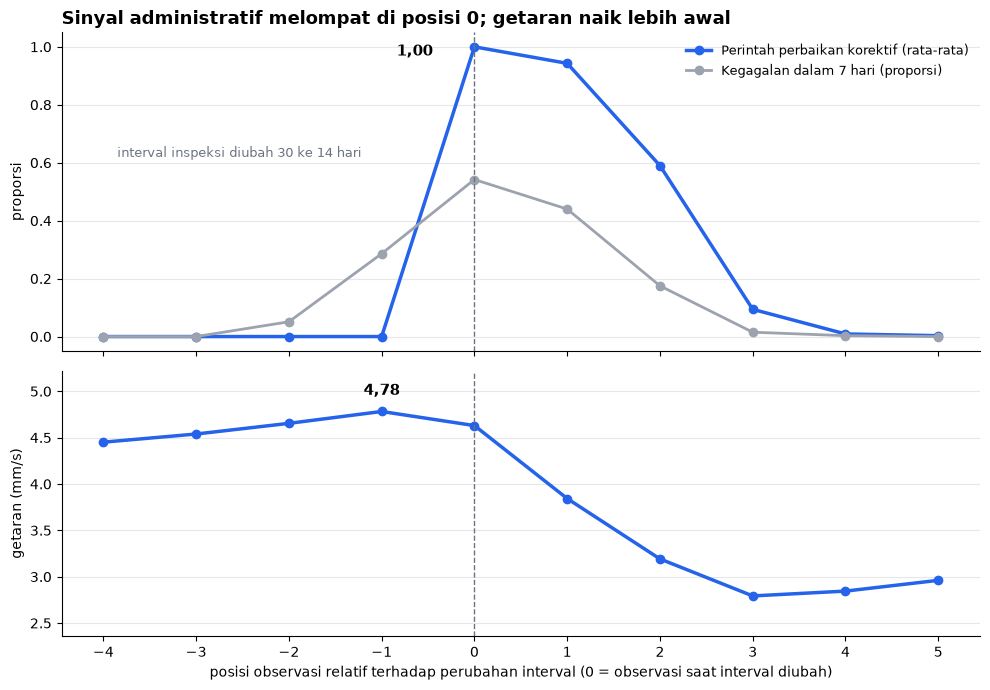

In [13]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True,
    gridspec_kw={"height_ratios": [1.2, 1]}
)

x = tabel_kejadian.index
biru = "#2563eb"
abu = "#9ca3af"

# Panel atas: sinyal administratif dan target
ax1.plot(x, tabel_kejadian["perintah_perbaikan"], marker="o", color=biru, linewidth=2.5,
         label="Perintah perbaikan korektif (rata-rata)")
ax1.plot(x, tabel_kejadian["tingkat_kegagalan"], marker="o", color=abu, linewidth=2,
         label="Kegagalan dalam 7 hari (proporsi)")
ax1.axvline(0, color="#6b7280", linestyle="--", linewidth=1)
ax1.annotate("1,00", xy=(0, 1.0), xytext=(-0.45, 0.97),
             fontweight="bold", ha="right", fontsize=11)
ax1.text(-3.85, 0.62, "interval inspeksi diubah 30 ke 14 hari",
         color="#6b7280", fontsize=9)
ax1.set_ylabel("proporsi")
ax1.set_title("Sinyal administratif melompat di posisi 0; getaran naik lebih awal",
              fontsize=13, fontweight="bold", loc="left")
ax1.legend(frameon=False, fontsize=9, loc="upper right")
ax1.grid(axis="y", alpha=0.3)

# Panel bawah: sinyal sensor
ax2.plot(x, tabel_kejadian["getaran"], marker="o", color=biru, linewidth=2.5)
ax2.margins(y=0.22)  # ruang di atas agar label angka tidak menempel tepi panel
ax2.axvline(0, color="#6b7280", linestyle="--", linewidth=1)
ax2.annotate("4,78", xy=(-1, tabel_kejadian.loc[-1, "getaran"]),
             xytext=(-1, tabel_kejadian.loc[-1, "getaran"] + 0.18),
             fontweight="bold", ha="center", fontsize=11)
ax2.set_ylabel("getaran (mm/s)")
ax2.set_xlabel("posisi observasi relatif terhadap perubahan interval "
               "(0 = observasi saat interval diubah)")
ax2.set_xticks(list(x))
ax2.grid(axis="y", alpha=0.3)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(FIG_DIR / "event_time.png", dpi=200, bbox_inches="tight")
print("Grafik disimpan di:", FIG_DIR / "event_time.png")
plt.show()

## Bagian 5 — Membagi data dengan benar

Model perlu diuji pada data yang belum pernah ia lihat. Cara pembagiannya menentukan apakah
hasil pengujian bisa dipercaya.

**Mengapa pembagian acak tidak sah di sini.** Di Bagian 1 kita menemukan mesin diamati tiap
lima hari sementara label menengok tujuh hari ke depan. Dua observasi berurutan dari mesin
yang sama karena itu memiliki jendela label yang bertumpang-tindih. Pembagian acak bisa
menaruh keduanya di sisi berbeda, sehingga model dinilai memakai informasi yang sudah ia
lihat.

**Pembagian berbasis waktu meniru kenyataan.** Di lapangan, model dilatih memakai masa lalu
dan dipakai pada masa depan. Pembagian berbasis waktu memeriksa persis kemampuan itu.

Batasnya ditaruh di persentil ke-70 dari waktu observasi: 70 persen data paling awal untuk
melatih, 30 persen sisanya untuk menguji.

In [14]:
df = df.sort_values("observation_timestamp").reset_index(drop=True)
batas = df["observation_timestamp"].quantile(0.70)

latih = df[df["observation_timestamp"] <= batas].copy()
uji = df[df["observation_timestamp"] > batas].copy()

print("Batas waktu :", batas.date())
print()
print("Data latih : {:5d} baris, base rate {:.1%}, sampai {}".format(
    len(latih), latih["fails_within_7d"].mean(), latih["observation_timestamp"].max().date()))
print("Data uji   : {:5d} baris, base rate {:.1%}, mulai {}".format(
    len(uji), uji["fails_within_7d"].mean(), uji["observation_timestamp"].min().date()))

minggu_uji = (uji["observation_timestamp"].max() - uji["observation_timestamp"].min()).days / 7
print()
print("Panjang jendela uji : {:.0f} minggu".format(minggu_uji))
print("Kegagalan di data uji:", int(uji["fails_within_7d"].sum()))

Batas waktu : 2024-10-25

Data latih :  7290 baris, base rate 4.8%, sampai 2024-10-25
Data uji   :  3124 baris, base rate 5.0%, mulai 2024-10-25

Panjang jendela uji : 18 minggu
Kegagalan di data uji: 157


Base rate di kedua sisi mirip, sekitar 5 persen. Itu pertanda baik: pembagian tidak
secara tidak sengaja memisahkan periode yang sangat berbeda.

## Bagian 6 — Membangun pembanding sederhana

Sebelum membangun model apa pun, kita perlu tahu seberapa jauh aturan paling sederhana bisa
sampai. Tanpa pembanding, angka model tidak punya makna.

Aturannya satu baris: **beri alarm jika mesin pernah mogok tak terencana dalam 14 hari
terakhir.** Aturan ini bisa ditulis siapa saja tanpa perlu machine learning.

Kalau model nanti hanya setara dengan ini, itu sendiri sudah merupakan temuan.

In [15]:
y_uji = uji["fails_within_7d"].values
alarm_aturan = (uji["unplanned_stops_14d"] >= 1).values

p_aturan = precision_score(y_uji, alarm_aturan)
r_aturan = recall_score(y_uji, alarm_aturan)
alarm_per_minggu_aturan = alarm_aturan.sum() / minggu_uji

print("ATURAN SEDERHANA: alarm jika unplanned_stops_14d >= 1")
print()
print("  Tangkapan (recall)    : {:.0%}".format(r_aturan))
print("  Ketepatan (precision) : {:.0%}".format(p_aturan))
print("  Alarm per minggu      : {:.0f}".format(alarm_per_minggu_aturan))
print()
print("Artinya: aturan ini menemukan {:.0f} dari setiap 100 kegagalan,".format(r_aturan * 100))
print("tetapi dari setiap 100 alarm hanya {:.0f} yang benar.".format(p_aturan * 100))

ATURAN SEDERHANA: alarm jika unplanned_stops_14d >= 1

  Tangkapan (recall)    : 90%
  Ketepatan (precision) : 9%
  Alarm per minggu      : 86

Artinya: aturan ini menemukan 90 dari setiap 100 kegagalan,
tetapi dari setiap 100 alarm hanya 9 yang benar.


## Bagian 7 — Membangun dan membandingkan model

Sekarang kita bangun model, tetapi dengan empat set fitur berbeda. Perbandingan antar-set
inilah yang membuktikan adanya kebocoran.

Empat set yang diuji:

1. **Semua kolom** — termasuk kolom administratif yang dicurigai bocor
2. **`corrective_orders_14d` saja** — satu kolom, tanpa sensor sama sekali
3. **Sensor + `unplanned_stops_14d`**
4. **Sensor saja** — ini yang merepresentasikan peringatan dini sungguhan

Model yang dipakai adalah `HistGradientBoostingClassifier`. Alasan pemilihannya sederhana
dan bisa dipertahankan: ia menangani nilai kosong secara bawaan, tidak menuntut penskalaan,
dan bekerja baik pada data tabular berukuran sedang. Notebook ini sengaja tidak menyetel
hiperparameter, karena persoalannya bukan di situ.

In [16]:
# Ubah kolom kategori menjadi angka 0/1 agar bisa dibaca model
for kolom in ["site", "machine_class"]:
    df = pd.concat([df, pd.get_dummies(df[kolom], prefix=kolom)], axis=1)

SENSOR = ["load_pct", "ambient_temp_c", "vibration_mm_s",
          "bearing_temp_c", "motor_current_a", "discharge_pressure_kpa"]
ADMIN = ["corrective_orders_14d", "unplanned_stops_14d", "inspection_interval_days"]
KATEGORI = [c for c in df.columns if c.startswith(("site_", "machine_class_"))]

# Bagi ulang setelah kolom kategori ditambahkan
latih = df[df["observation_timestamp"] <= batas]
uji = df[df["observation_timestamp"] > batas]
y_latih = latih["fails_within_7d"]
y_uji = uji["fails_within_7d"]

SET_FITUR = {
    "Semua kolom": SENSOR + ADMIN + KATEGORI,
    "corrective_orders_14d saja": ["corrective_orders_14d"],
    "Sensor + unplanned_stops_14d": SENSOR + ["unplanned_stops_14d"] + KATEGORI,
    "Sensor saja": SENSOR + KATEGORI,
}

hasil = []
model_tersimpan = {}

for nama, fitur in SET_FITUR.items():
    model = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)
    model.fit(latih[fitur], y_latih)
    skor = model.predict_proba(uji[fitur])[:, 1]
    model_tersimpan[nama] = (model, fitur, skor)
    hasil.append({
        "Set fitur": nama,
        "PR-AUC": round(average_precision_score(y_uji, skor), 3),
        "ROC-AUC": round(roc_auc_score(y_uji, skor), 3),
    })

tabel_hasil = pd.DataFrame(hasil)
print("Acuan pembanding — tebakan acak memberi PR-AUC sekitar {:.3f}".format(y_uji.mean()))
print()
tabel_hasil

Acuan pembanding — tebakan acak memberi PR-AUC sekitar 0.050



,Set fitur,PR-AUC,ROC-AUC
0,Semua kolom,0.697,0.950
1,corrective_orders_14d saja,0.366,0.867
2,Sensor + unplanned_stops_14d,0.234,0.849
3,Sensor saja,0.220,0.825


**Baris kedua adalah inti argumen Anda.**

Satu kolom bernilai 0 atau 1, tanpa satu pun pembacaan sensor, mengungguli model yang
memakai keenam sensor sekaligus.

Mengapa itu mustahil untuk peringatan dini yang sah: sensor mengukur kondisi fisik mesin,
dan kegagalan fisik seharusnya didahului perubahan fisik. Kalau catatan administratif lebih
prediktif daripada fisik mesinnya sendiri, catatan itu bukan gejala — ia adalah bukti bahwa
seseorang sudah mengetahui masalahnya.

Sekarang satu pemeriksaan tambahan yang menunjukkan kejujuran analisis: apa yang terjadi
kalau data dibagi secara acak.

In [17]:
fitur_semua = SET_FITUR["Semua kolom"]

X_latih_acak, X_uji_acak, y_latih_acak, y_uji_acak = train_test_split(
    df[fitur_semua], df["fails_within_7d"],
    test_size=0.30, random_state=RANDOM_STATE, stratify=df["fails_within_7d"],
)

model_acak = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)
model_acak.fit(X_latih_acak, y_latih_acak)
skor_acak = model_acak.predict_proba(X_uji_acak)[:, 1]

print("Pembagian acak, semua kolom   : PR-AUC {:.3f}".format(
    average_precision_score(y_uji_acak, skor_acak)))
print("Pembagian waktu, semua kolom  : PR-AUC {:.3f}".format(
    tabel_hasil.loc[0, "PR-AUC"]))

Pembagian acak, semua kolom   : PR-AUC 0.636
Pembagian waktu, semua kolom  : PR-AUC 0.697


Hasil ini perlu disampaikan apa adanya, dan justru menguatkan posisi Anda.

Biasanya pembagian acak menggelembungkan skor. Di sini tidak. Artinya kebocorannya **tidak
terletak pada cara data dibagi, melainkan pada isi kolomnya.**

Pembagian berbasis waktu tetap dipakai karena struktur panel data memang menuntutnya, bukan
karena ia kebetulan menurunkan angka. Membedakan dua alasan itu adalah tanda penilaian yang
matang, dan kemungkinan besar akan ditanyakan.

## Bagian 8 — Menerjemahkan ke satuan operasional

Model menghasilkan skor antara 0 dan 1 untuk tiap observasi. Untuk memakainya, seseorang
harus memilih ambang: di atas berapa sebuah mesin diberi alarm.

Ambang yang berbeda menghasilkan pertukaran yang berbeda. Pemilik proses tidak bisa memilih
berdasarkan PR-AUC; ia butuh angka dalam satuan yang ia kenali, yaitu **berapa teknisi yang
harus dikirim tiap minggu.**

Tabel di bawah dihitung memakai model **sensor saja**, karena hanya itu yang
merepresentasikan peringatan dini sungguhan.

In [18]:
_, _, skor_sensor = model_tersimpan["Sensor saja"]

presisi, tangkapan, ambang = precision_recall_curve(y_uji, skor_sensor)
total_kegagalan = int(y_uji.sum())

baris_operasi = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    i = int(np.argmin(np.abs(tangkapan - target)))
    ambang_i = ambang[min(i, len(ambang) - 1)]
    n_alarm = int((skor_sensor >= ambang_i).sum())
    baris_operasi.append({
        "Tangkapan": "{:.0%}".format(tangkapan[i]),
        "Ketepatan": "{:.0%}".format(presisi[i]),
        "Alarm per minggu": round(n_alarm / minggu_uji),
        "Kegagalan tertangkap per minggu": round(tangkapan[i] * total_kegagalan / minggu_uji, 1),
    })

tabel_operasi = pd.DataFrame(baris_operasi)
print("Model sensor saja — jendela uji {:.0f} minggu, {} kegagalan".format(
    minggu_uji, total_kegagalan))
print()
print("Pembanding, aturan satu baris: tangkapan {:.0%}, ketepatan {:.0%}, {:.0f} alarm/minggu".format(
    r_aturan, p_aturan, alarm_per_minggu_aturan))
print()
tabel_operasi

Model sensor saja — jendela uji 18 minggu, 157 kegagalan

Pembanding, aturan satu baris: tangkapan 90%, ketepatan 9%, 86 alarm/minggu



,Tangkapan,Ketepatan,Alarm per minggu,Kegagalan tertangkap per minggu
0,50%,20%,22,4.4
1,60%,16%,32,5.2
2,70%,14%,42,6.1
3,80%,11%,64,7.0
4,90%,10%,80,7.8


**Bandingkan baris terakhir tabel dengan aturan satu baris.**

Pada tangkapan yang sama, keduanya menghasilkan jumlah alarm yang praktis identik.
Model machine learning tidak mengungguli aturan yang bisa ditulis di selembar tisu.

Terjemahan operasionalnya, dan inilah kalimat yang akan diingat audiens bisnis: pada
ketepatan 10 persen, dari sepuluh mesin yang didatangi teknisi, sembilan dalam keadaan baik.
Tim lapangan yang mengalami itu selama dua minggu akan berhenti menanggapi alarm — dan
setelah itu, angka tangkapan 90 persen di atas kertas menjadi tidak berarti.

Titik operasi yang paling bisa dipertahankan adalah tangkapan 50 persen dengan ketepatan
20 persen dan sekitar 22 alarm per minggu. Pilihan itu menerima bahwa separuh kegagalan
tetap lolos.

Penentuan titik operasi yang benar memerlukan satu angka yang belum tersedia: **berapa kali
lebih mahal satu kegagalan yang terlewat dibandingkan satu inspeksi yang sia-sia.** Angka
itu harus datang dari pemilik proses, bukan dari analis. Karena itu tabel disajikan utuh.

## Bagian 9 — Ringkasan

Sel di bawah mencetak ulang seluruh angka kunci dalam satu tempat. Gunakan keluarannya
untuk mengisi README dan menyiapkan presentasi.

In [19]:
print("=" * 70)
print("RINGKASAN TEMUAN")
print("=" * 70)
print()
print("DATA")
print("  {} observasi, {} mesin, {} sampai {}".format(
    len(df), df["machine_id"].nunique(),
    df["observation_timestamp"].min().date(), df["observation_timestamp"].max().date()))
print("  Base rate kegagalan: {:.1%}".format(base_rate))
print()
print("KUALITAS DATA")
print("  {} baris vibration_mm_s bernilai -999 (kode data hilang)".format(n_sentinel))
print("  {} baris machine_id + timestamp terduplikasi".format(n_dup))
print()
print("KEBOCORAN")
print("  corrective_orders_14d melompat 0,000 -> 1,000 tepat di posisi perubahan interval")
print("  Tingkat kegagalan saat interval 14 hari: {:.0%}, saat 30 hari: {:.0%}".format(
    df.loc[df.inspection_interval_days == 14, "fails_within_7d"].mean(),
    df.loc[df.inspection_interval_days == 30, "fails_within_7d"].mean()))
print()
print("PERFORMA (pembagian berbasis waktu, acuan acak = {:.3f})".format(y_uji.mean()))
for _, r in tabel_hasil.iterrows():
    print("  {:30s} PR-AUC {:.3f}".format(r["Set fitur"], r["PR-AUC"]))
print()
print("OPERASIONAL (model sensor saja)")
print("  Aturan satu baris : tangkapan {:.0%}, {:.0f} alarm/minggu".format(
    r_aturan, alarm_per_minggu_aturan))
print("  Model pada tangkapan setara: lihat tabel Bagian 8")
print()
print("REKOMENDASI")
print("  Belum layak diterapkan. Skor utama bersandar pada kolom yang terisi")
print("  setelah tim pemeliharaan menemukan masalahnya. Setelah kolom itu dibuang,")
print("  model setara dengan aturan satu baris.")
print()
print("  Yang mengubah keputusan ini: konfirmasi pemilik data bahwa kedua kolom")
print("  administratif benar-benar terisi sebelum observasi dicatat.")
print("=" * 70)

RINGKASAN TEMUAN

DATA
  10414 observasi, 120 mesin, 2024-01-01 sampai 2025-02-28
  Base rate kegagalan: 4.9%

KUALITAS DATA
  10 baris vibration_mm_s bernilai -999 (kode data hilang)
  80 baris machine_id + timestamp terduplikasi

KEBOCORAN
  corrective_orders_14d melompat 0,000 -> 1,000 tepat di posisi perubahan interval
  Tingkat kegagalan saat interval 14 hari: 21%, saat 30 hari: 1%

PERFORMA (pembagian berbasis waktu, acuan acak = 0.050)
  Semua kolom                    PR-AUC 0.697
  corrective_orders_14d saja     PR-AUC 0.366
  Sensor + unplanned_stops_14d   PR-AUC 0.234
  Sensor saja                    PR-AUC 0.220

OPERASIONAL (model sensor saja)
  Aturan satu baris : tangkapan 90%, 86 alarm/minggu
  Model pada tangkapan setara: lihat tabel Bagian 8

REKOMENDASI
  Belum layak diterapkan. Skor utama bersandar pada kolom yang terisi
  setelah tim pemeliharaan menemukan masalahnya. Setelah kolom itu dibuang,
  model setara dengan aturan satu baris.

  Yang mengubah keputusan ini:

---

## Apa yang harus dilakukan setelah ini

1. **Jalankan ulang dari nol.** Restart kernel, lalu Run All. Pastikan notebook jalan
   bersih dari atas ke bawah tanpa error. Ini yang dinilai sebagai *reproducibility*.
2. **Isi README.md** memakai keluaran Bagian 9.
3. **Isi ASSUMPTIONS.md** dengan asumsi yang ditemui sepanjang notebook: nilai `-999`,
   duplikat, `unknown` pada `machine_class`, dan bulan pertama yang base rate-nya rendah.
4. **Ambil `figures/event_time.png`** sebagai slide utama presentasi.
5. **Latih menjelaskan Bagian 4 dengan suara keras.** Kalau Anda bisa menjelaskan tabel
   waktu kejadian tanpa membaca catatan, sisanya akan mengikuti.

### Pertanyaan yang kemungkinan besar diajukan

**"Kenapa tidak pakai akurasi?"**
Base rate hanya 4,9 persen. Model yang selalu menjawab aman memperoleh akurasi 95,1 persen
tanpa menemukan satu pun kegagalan.

**"Kenapa pembagiannya berbasis waktu?"**
Mesin diamati tiap lima hari, label menengok tujuh hari ke depan, jadi jendela label baris
berdekatan bertumpang-tindih. Pembagian acak akan menilai model memakai informasi yang sudah
ia lihat. Pembagian waktu juga meniru cara model dipakai sungguhan.

**"Bagaimana Anda tahu kolom itu bocor?"**
Nilainya melompat dari tepat 0,000 ke tepat 1,000 di observasi yang sama saat interval
inspeksi dipendekkan. Proses fisik tidak menghasilkan lompatan sebersih itu. Dan satu kolom
biner itu sendirian mengungguli keenam sensor digabung, yang mustahil kalau ia benar-benar
gejala.

**"Apa bagian paling lemah dari analisis ini?"**
Saya belum bisa memastikan arah sebab-akibatnya dari data saja. Saya menyimpulkan kolom itu
terisi *setelah* masalah diketahui, tetapi itu kesimpulan dari pola, bukan dari dokumentasi
lineage. Karena itu pertanyaan pertama saya ke pemilik data adalah soal waktu pengisian
kolom tersebut.

**"Kalau punya dua minggu lagi, apa yang Anda kerjakan?"**
Fitur tren per mesin, bukan nilai mentah: kenaikan getaran terhadap tingkat dasar mesin itu
sendiri pada beberapa observasi sebelumnya. Panel bawah grafik menunjukkan sinyalnya ada;
yang belum dilakukan adalah mengubahnya menjadi fitur.